## imports

In [1]:
!pip install datasets transformers rouge-score nltk

     |████████████████████████████████| 312 kB 12.2 MB/s 
     |████████████████████████████████| 3.8 MB 38.5 MB/s 
     |████████████████████████████████| 134 kB 48.9 MB/s 
     |████████████████████████████████| 212 kB 48.7 MB/s 
     |████████████████████████████████| 1.1 MB 38.8 MB/s 
     |████████████████████████████████| 67 kB 4.9 MB/s 
     |████████████████████████████████| 127 kB 51.1 MB/s 
     |████████████████████████████████| 596 kB 49.2 MB/s 
     |████████████████████████████████| 895 kB 43.7 MB/s 
     |████████████████████████████████| 6.5 MB 42.4 MB/s 
     |████████████████████████████████| 271 kB 39.3 MB/s 
     |████████████████████████████████| 94 kB 1.9 MB/s 
     |████████████████████████████████| 144 kB 39.8 MB/s 
  Attempting uninstall: urllib3
    Found existing installation: urllib3 1.24.3
    Uninstalling urllib3-1.24.3:
      Successfully uninstalled urllib3-1.24.3
  Attempting uninstall: pyyaml
    Found existing installation: PyYAML 3.13
    Uninstallin

In [2]:
import datasets
from datasets import Dataset
from datasets import load_dataset, load_metric

import os
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from IPython.display import display, HTML
import matplotlib.pyplot as plt

import torch
from transformers import AutoTokenizer,T5Tokenizer, T5ForConditionalGeneration
from transformers import pipeline
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

## load the dataset

In [3]:
df_news = pd.read_csv('news_summary - train.csv', 
                       engine='python',
                       encoding='unicode_escape') 

In [4]:
print(df_news.shape)
df_news.head()

(149, 2)


,Summary,Text
0,As many as 13 people died while travelling in ...,Motorman Mahendra Prasad called up the railway...
1,The Gujarat Congress MLAs staying in a Bengalu...,Bored in confines of a sprawling resort in Ben...
2,According to a recently published US-based res...,There is only a 5% chance that the Earth will ...
3,A swarm of bees reportedly attacked a Hyderaba...,After a swarm of bees held up a Hyderabad-Pune...
4,"Flight Lt Shikha Pandey, a member of the India...","New Delhi, Aug 1 (PTI) Flight Lt Shikha Pandey..."


In [5]:
df_news = df_news[['Text', 'Summary']]
df_news.head()

,Text,Summary
0,Motorman Mahendra Prasad called up the railway...,As many as 13 people died while travelling in ...
1,Bored in confines of a sprawling resort in Ben...,The Gujarat Congress MLAs staying in a Bengalu...
2,There is only a 5% chance that the Earth will ...,According to a recently published US-based res...
3,After a swarm of bees held up a Hyderabad-Pune...,A swarm of bees reportedly attacked a Hyderaba...
4,"New Delhi, Aug 1 (PTI) Flight Lt Shikha Pandey...","Flight Lt Shikha Pandey, a member of the India..."


## preprocessing data

In [6]:
# clean data
def clean_df(df):
  # remove email starts
  df.text = df.text.replace(re.compile(r"From|\S*@\S*\s?|Subject"), "")

  # remove extra spaces
  df.text = df.text.replace(re.compile(r"\s+"), " ")

  # remove -, _ and :
  df.text = df.text.replace(re.compile(r"[\-_,;:]"), " ")

  # remove other chars
  df.text = df.text.replace(re.compile(r"[^a-zA-Z0-9\.,$# ]"), "")

  df.text = df.text.apply(lambda x: x.strip())

  return df

In [7]:
df_news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Text     147 non-null    object
 1   Summary  149 non-null    object
dtypes: object(2)
memory usage: 2.5+ KB


In [8]:
# dropping rows with null ctext
df_news = df_news.dropna()
df_news.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 147 entries, 0 to 148
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Text     147 non-null    object
 1   Summary  147 non-null    object
dtypes: object(2)
memory usage: 3.4+ KB


In [9]:
df_news.rename(columns={"Summary": "summary", "Text": "full_text"}, inplace=True)
df_news.shape

(147, 2)

In [10]:
display(HTML(df_news.sample(3).to_html()))

### length analysis

In [11]:
# getting length for each column
for col in df_news.columns.tolist():
    df_news[col+"_num_words"] = df_news[col].apply(lambda x: len(x.split()))
df_news.head()

,full_text,summary,full_text_num_words,summary_num_words
0,Motorman Mahendra Prasad called up the railway...,As many as 13 people died while travelling in ...,316,60
1,Bored in confines of a sprawling resort in Ben...,The Gujarat Congress MLAs staying in a Bengalu...,109,60
2,There is only a 5% chance that the Earth will ...,According to a recently published US-based res...,944,60
3,After a swarm of bees held up a Hyderabad-Pune...,A swarm of bees reportedly attacked a Hyderaba...,389,59
4,"New Delhi, Aug 1 (PTI) Flight Lt Shikha Pandey...","Flight Lt Shikha Pandey, a member of the India...",93,59


In [12]:
cols = ['summary_num_words', 'full_text_num_words']
df_news[cols].describe()

,summary_num_words,full_text_num_words
count,147.000000,147.000000
mean,58.251701,443.877551
std,2.454639,403.011164
min,50.000000,67.000000
25%,57.000000,250.500000
50%,59.000000,357.000000
75%,60.000000,501.500000
max,60.000000,3093.000000


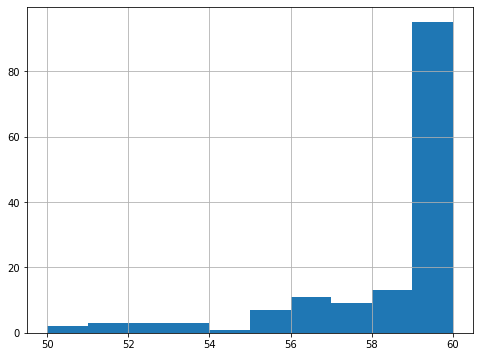

In [13]:
df_news["summary_num_words"].hist(bins=10, figsize=(8,6))

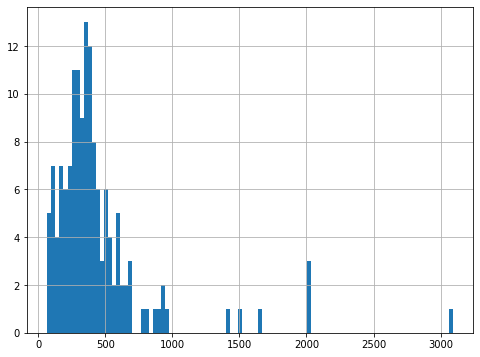

In [14]:
df_news["full_text_num_words"].hist(bins=100, figsize=(8,6))

(0.0, 1500.0)

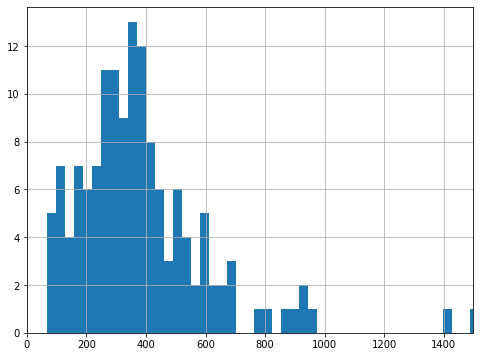

In [15]:
# zoomed-in
axes = df_news["full_text_num_words"].hist(bins=100, figsize=(8,6))
axes.set_xlim(0, 1500)

## tokenizer

In [16]:
# Tokenizer will tokenize the inputs by converting the tokens to their corresponding IDs in the pretrained vocabulary
# put it in a format the model expects, as well as generate the other inputs that the model requires

# base_model = "t5-large"
base_model = "t5-small"
tokenizer = AutoTokenizer.from_pretrained(base_model)

Downloading:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/773k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/1.32M [00:00<?, ?B/s]

## prep data for model

In [30]:
prefix = "summarize: "

max_input_length = int(df_news['full_text_num_words'].describe()['mean'])
max_target_length = int(df_news['summary_num_words'].describe()['mean'])

# data has full_text and summary
def preprocess_function(data):
    full_texts = [prefix + doc for doc in data['full_text']]

    # padding will be dealt with data collator, so we pad examples to the longest length in the batch and not the whole dataset.
    model_inputs = tokenizer(full_texts, max_length=max_input_length, truncation=True)

    # setup the tokenizer for summary
    with tokenizer.as_target_tokenizer():
        summary = tokenizer(data['summary'], max_length=max_target_length, truncation=True)

    # for summary we don't need attention mask
    # model_inputs will have input_ids and attention mask of full text, input_ids (which we store as labels) of summary 
    model_inputs["labels"] = summary["input_ids"]
    return model_inputs

In [31]:
# split data into train/test
df_train, df_test = train_test_split(df_news, test_size=0.20, random_state=42)
df_train.shape, df_test.shape

((117, 4), (30, 4))

In [32]:
dataset_train = Dataset.from_pandas(df_train[['full_text', 'summary']])
dataset_test = Dataset.from_pandas(df_test[['full_text', 'summary']])

len(dataset_train), len(dataset_test)

(117, 30)

In [33]:
# apply preprocess_function to all elems of dataset train/test object
# batched=True to encode the texts by batches together
# this also caches the results to avoid spending time on this step the next time we run the code
# we can pass load_from_cache_file=False inside map(...) to not use the cached files and force the preprocessing to be applied again

dataset_train_tokenized = dataset_train.map(preprocess_function, batched=True)
dataset_test_tokenized = dataset_test.map(preprocess_function, batched=True)

  0%|          | 0/1 [00:00<?, ?ba/s]

  0%|          | 0/1 [00:00<?, ?ba/s]

In [34]:
len(dataset_train_tokenized), len(dataset_test_tokenized)

(117, 30)

## fine-tuning the model

In [35]:
# load rouge metric
metric = load_metric("rouge")

# load t5-base model
model_summ = AutoModelForSeq2SeqLM.from_pretrained(base_model)

Downloading:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/231M [00:00<?, ?B/s]

### o/p check before finetuning

In [36]:
def get_summary(summarizer_object, text, min_length=10, max_length=100):
    summary = [elem['summary_text'] for elem in summarizer_object(text, min_length=min_length, max_length=max_length)]
    display(HTML(pd.DataFrame({"text":text, "summary":summary}).to_html()))

In [37]:
# pass finetuned model and tokenizer
# device=0 is gpu
summarizer_before_train = pipeline("summarization", model=model_summ, tokenizer=tokenizer, device=0)

In [38]:
# returns a list of dict with summary 
summarizer_before_train(["This is quite good. Hello World", "This is quite good"], min_length=3, max_length=3)

[{'summary_text': 'Hello World'}, {'summary_text': 'this is'}]

In [39]:
get_summary(summarizer_before_train, df_train[:1].full_text.tolist())

,text,summary
0,"After a controversy started over authorities leaving a copy of the Bhagavad Gita next to the statue of former President APJ Abdul Kalam at the memorial built for him at Rameswaram, a Bible and Quran were also placed to end the row.Prime Minister Narendra Modi had inaugurated the memorial at Peikulam, Rameswaram, the birthplace of Kalam, on July 27.The government was applauded for the memorial but it was also criticised for putting the Bhagavad Gita next to the statue of Kalam playing a 'veena'.When questioned, an official explained that Kalam loved the veena and that he often quoted from the Bhagavad Gita, but no official came forward to prove the claim.The controversy began when MDMK leader Vaiko questioned if Bhagavad Gita is more sacred than the Tamil book 'Thirukural' written by Thiruvalluvar, and alleged that the Centre is trying to saffronize even the legacy of Kalam.Not wanting the controversy to grow bigger, Kalam's grand nephew Sheik Saleem placed a Bible and a Quran next to the Bhagavad Gita, to prove that Kalam was a man who was beyond religion who has a grand dream of a better India.The next controversy waiting to happen is the vast usage of saffron like color in his memorial which can anytime be picked up by Tamil politicians.","a copy of the Bhagavad Gita next to the statue of former president APJ Abdul Kalam at the memorial built for him at Rameswaram on July 27 . the government was applauded for the memorial, but it was also criticised for putting it next to a statue playing a 'veena'"


In [40]:
get_summary(summarizer_before_train, df_test[:1].full_text.tolist())

,text,summary
0,"More than 100 military veterans have in a letter to Prime Minister Narendra Modi condemned targeting of Muslims and Dalits by ?self-appointed protectors of Hinduism?, saying India?s strength is its diversity, media reports said on Monday.The letter also expressed concern over alleged climate of fear and suppression of dissent, as it backed the ?Not In My Name? campaign that saw people across the country holding protest demonstrations against mob violence and cow vigilantism.?We can no longer look away. We would be doing a disservice to our country if we do not stand up and speak for the liberal and secular values that our Constitution espouses. Our diversity is our greatest strength,? The Telegraph quoted the letter as saying. The letter has also been sent to state chief ministers.The letter signed by retired army, naval and air force officers said prevalent atmosphere was against everything that the armed forces and the Constitution stood for, a report in NDTV said.?We are witness to unprecedented attacks on society at large by the relentless vigilantism of self-appointed protectors of Hinduism. We condemn the targeting of Muslims and Dalits,? the letter said.The armed forces stood for unity in diversity and differences in religion, language, caste or culture had never come in the way of servicemen performing their duty, the veteran said.India has recently seen a rise in violence in the name of cow, held sacred by many Hindus. Several states have enacted laws and prescribed stringent punishment for smuggling and slaughtering of the animal, which is banned in most parts of the country. Muslims and Dalits have been the worst hit by cow vigilantism, which has also been condemned by Prime Minister Narendra Modi.",more than 100 military veterans have in a letter to Prime Minister Narendra Modi condemning targeting of Muslims and Dalits . the letter expressed concern over alleged climate of fear and suppression of dissent . it backed the ?Not In My Name? campaign that saw people across the country holding protest demonstrations against mob violence and cow vigilantism .


### training

In [41]:
batch_size = 8
epochs = 1

args = Seq2SeqTrainingArguments("summarization_t5_v2", 
                                num_train_epochs=epochs,
                                # we will evaluate after every 100 batch (100*8 = 800 samples)
                                evaluation_strategy = "steps",
                                logging_steps = 100,
                                learning_rate=2e-5,
                                weight_decay=0.01,
                                per_device_train_batch_size=batch_size, 
                                per_device_eval_batch_size=batch_size,
                                # max number of times to save model
                                save_total_limit=3, 
                                predict_with_generate=True,
                                fp16=True, 
                                load_best_model_at_end = True, 
                                eval_steps = 50,
                                )


In [42]:
# calculate rouge scores
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    
    # Replace -100 in the labels as we can't decode them.
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    
    # Rouge expects a newline after each sentence
    decoded_preds = ["\n".join(nltk.sent_tokenize(pred.strip())) for pred in decoded_preds]
    decoded_labels = ["\n".join(nltk.sent_tokenize(label.strip())) for label in decoded_labels]
    
    result = metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
    # Extract a few results
    result = {key: value.mid.fmeasure * 100 for key, value in result.items()}
    
    # Add mean generated length
    prediction_lens = [np.count_nonzero(pred != tokenizer.pad_token_id) for pred in predictions]
    result["gen_len"] = np.mean(prediction_lens)
    
    return {k: round(v, 4) for k, v in result.items()}

In [43]:
# will pad the inputs and the labels to maximum length in a batch
# so we pad examples to the longest length in the batch and not the whole dataset
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model_summ)
model_trainer = Seq2SeqTrainer(model_summ,
                               args,
                               train_dataset = dataset_train_tokenized, eval_dataset = dataset_test_tokenized,
                               data_collator = data_collator, tokenizer = tokenizer, compute_metrics = compute_metrics)

Using amp half precision backend


In [44]:
# train the model
model_trainer.train()

The following columns in the training set  don't have a corresponding argument in `T5ForConditionalGeneration.forward` and have been ignored: summary, __index_level_0__, full_text. If summary, __index_level_0__, full_text are not expected by `T5ForConditionalGeneration.forward`,  you can safely ignore this message.
/usr/local/lib/python3.7/dist-packages/transformers/optimization.py:309: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  FutureWarning,
***** Running training *****
  Num examples = 117
  Num Epochs = 1
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 15


Step,Training Loss,Validation Loss




Training completed. Do not forget to share your model on huggingface.co/models =)




TrainOutput(global_step=15, training_loss=2.669824981689453, metrics={'train_runtime': 16.6096, 'train_samples_per_second': 7.044, 'train_steps_per_second': 0.903, 'total_flos': 13700978343936.0, 'train_loss': 2.669824981689453, 'epoch': 1.0})

## predictions

In [45]:
# pass finetuned model and tokenizer
summarizer = pipeline("summarization", model=model_summ, tokenizer=tokenizer, device=0)

In [46]:
idx = random.sample(range(0, len(df_news)), k=3)
get_summary(summarizer, df_news.iloc[idx].full_text.tolist())

Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


,text,summary
0,"Two Chinese nationals, on Monday, managed to replace a piece of diamond jewellery with a fake one at Mumbai?s India International Jewellery Show. However, swift action by Central Industrial Security Force (CISF) led to their arrest at Mumbai airport.The diamond, worth Rs34 lakh, was recovered from a bottle of shampoo.The CISF later also provided security at the India International Jewellery Show (IIJS)-2017, which was being held at Bombay Exhibition Center, Goregaon. ?On July 31, at 3:45 pm, Gem Jewellery Export Promotion Council (GJEPC) informed us that two Chinese nationals, while trying to strike a deal, cleverly switched and replaced a diamond piece weighing 5.4 carats, approximately costing Rs34 lakhs, with a fake piece,? said a CISF official.As soon as the information was received, a combined team of CISF personnel and council members spread out in the hall to locate the Chinese nationals and prevent them from exiting the venue. Meanwhile, their photographs were also taken from the council registration office and provided at all the gates. Subsequently, their movements were traced through CCTV footage, wherein it was revealed that the two Chinese nationals had already left the show. ?Once it was established that they had left, their passport details, registration details and photographs were taken from the council and sent to the Foreigner Regional Registration Office (FRRO) Mumbai and CISF?s airport incharge,? the official added.On the basis of the information, the immigration officials were able to detect the two Chinese nationals who were to board Air India flight AI 314 from Mumbai to Osaka via Delhi-Hongkong scheduled to depart at 7:45 pm. ?It was found that there were not carrying any check in luggage and only two small-shaving kit sized bags were in their possession. The individuals had also changed their clothes from what they were wearing at the exhibition,? the officer said.Because the size of the diamond was small, the X-ray machine could not detect it and therefore, they were then interrogated with the help of a Chinese interpreter, after being off-loaded from the plane.During interrogation, they revealed that the diamond was concealed in a small shampoo bottle, which was subsequently recovered.",two nationals swapped a piece of diamond jewellery with a fake one . the pair were arrested at the Mumbai International Jewellery Show on july 31 . CISF later provided security at the IIJS-2017 .
1,"The government has no ?accurate data? regarding illegal migrants who have entered India, the Lok Sabha was informed on Tuesday.Minister of state for home Kiren Rijiju also said that any particular community cannot be ?branded? for having alleged links with terrorists and terrorism. ?We cannot say that,? he said during the Question Hour.He agreed that several illegal migrants have acquired documents to make their stay in the country legal.Responding to supplementaries, he said since these people have entered the country in a ?clandestine and surreptitious manner?, ?naturally? official figures would be impossible.The Centre has asked the states to set up special task forces in each of the districts for detection, identification and interception of illegal migrants.The states also have powers under the 1946 Foreigners Act to deport illegal migrants. Detention centres have also been set up for detaining suspected illegal migrants, pending their deportation.He said illegal migrants disturbed the demographic profile of certain areas and create problems.Responding to the issue of Rohingya refugees, he said they are concentrated in Jammu and Kashmir.When asked by opposition members whether government has set up ?concentration camps? for them, he said no concentration camps have been established by the government but the refugees themselves have concentrated themselves there.","the government has no ?accurate data? about illegal migrants who have entered the country, the Lok Sabha was informed on Tuesday . he agre

In [51]:
summarizer_loaded = pipeline("summarization", model=model_summ, tokenizer=tokenizer, device=0)

## evaluation

In [53]:
df_test = pd.read_csv('news_summary - test.csv', 
                       engine='python',
                       encoding='unicode_escape')

In [54]:
df_test.rename(columns={"Summary": "summary", "Text": "full_text"}, inplace=True)

In [55]:
# in case GPU goes out of memory we can move model to CPU and create summarizer object
model_summ.to("cpu")
summarizer_loaded_cpu = pipeline("summarization", model=model_summ, tokenizer=tokenizer)

In [80]:
df_test.shape

(49, 2)

In [90]:
# get all predictions
text_test = df_test.full_text.tolist()
summary_test = df_test.summary.tolist()
summary_pred = []

In [91]:
from tqdm import tqdm

In [92]:
batch_size = 8
start_idx = 0
# we are processing data in batches
for i in tqdm(range(0, len(text_test[start_idx:]), batch_size)):
    batch = int(i/batch_size)
    batch_text = text_test[start_idx+i : start_idx+i+batch_size]
    summary_pred += [elem['summary_text'] for elem in summarizer_loaded_cpu(batch_text, min_length=10, max_length=100)]

100%|██████████| 7/7 [04:39<00:00, 39.96s/it]


In [93]:
len(summary_pred)

49

In [94]:
results = metric.compute(predictions=summary_pred,
                         references=summary_test)
print(results)

for key in ["rouge1", "rouge2", "rougeL"]:
    print(key, "low:", results[key].low.fmeasure)
    print(key, "mid:", results[key].mid.fmeasure)
    print(key, "high:", results[key].high.fmeasure, end="\n\n")

{'rouge1': AggregateScore(low=Score(precision=0.4500591254257988, recall=0.30589002784667213, fmeasure=0.3617030919470077), mid=Score(precision=0.49738118283003474, recall=0.3425682289269909, fmeasure=0.39995088840494253), high=Score(precision=0.545216103276578, recall=0.3804532133736936, fmeasure=0.4385093481743236)), 'rouge2': AggregateScore(low=Score(precision=0.18387059519418303, recall=0.1256647459160264, fmeasure=0.14733163973400118), mid=Score(precision=0.22890311628290075, recall=0.1570428692256598, fmeasure=0.18365689189615458), high=Score(precision=0.2760573368471821, recall=0.18931263375522178, fmeasure=0.2212957170130013)), 'rougeL': AggregateScore(low=Score(precision=0.3233307028878702, recall=0.21847906973198508, fmeasure=0.25985499031775205), mid=Score(precision=0.36544402918368046, recall=0.24863373532125232, fmeasure=0.29216601607500725), high=Score(precision=0.4110867793127158, recall=0.28026846156182483, fmeasure=0.32844843469772544)), 'rougeLsum': AggregateScore(low

In [96]:
from nltk.translate.bleu_score import sentence_bleu

In [97]:
bleu = []
for x, y in zip(summary_test, summary_pred):
  bleu.append(sentence_bleu([x.split()], y.split()))

/usr/local/lib/python3.7/dist-packages/nltk/translate/bleu_score.py:490: UserWarning: 
Corpus/Sentence contains 0 counts of 2-gram overlaps.
BLEU scores might be undesirable; use SmoothingFunction().
  warnings.warn(_msg)


In [98]:
print('rouge1 :', np.mean(rouge1))
print('rouge2 :', np.mean(rouge2))
print('rougeL :', np.mean(rougeL))
print('bleu   :',   np.mean(bleu))

rouge1 : 0.4131190627721119
rouge2 : 0.19285629940866025
rougeL : 0.30366722367751375
bleu   : 0.5869985043479613


In [99]:
df_test['pred'] = summary_pred

In [101]:
df_test.to_csv('t5.csv', index=False)